## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

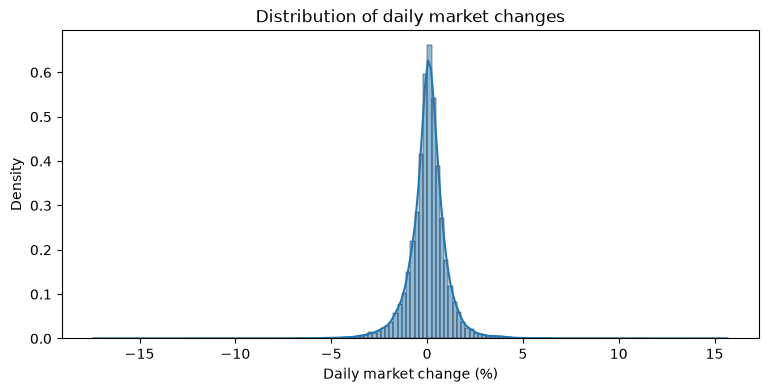

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

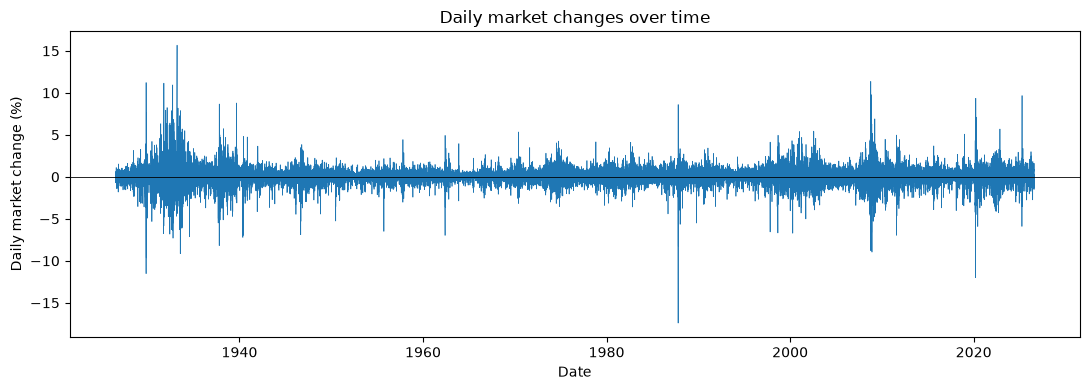

In [11]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [12]:
# make a categorical column "direction_t" 
direction_categories = ['Down / flat', 'Up']
np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat')

df['direction_t'] = pd.Categorical(
    np.where(df['market_return_pct'] > 0, 'Up', 'Down / flat'),
    categories=direction_categories,
    ordered=True
)

In [17]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_tp1'].shift(-1)

In [19]:
pd.crosstab(df['direction_t'], df['direction_tp1'], normalize=True, margins=True)

direction_tp1,Down / flat,Up,All
direction_t,,,
Down / flat,0.204921,0.247937,0.452858
Up,0.247975,0.299167,0.547142
All,0.452896,0.547104,1.000000


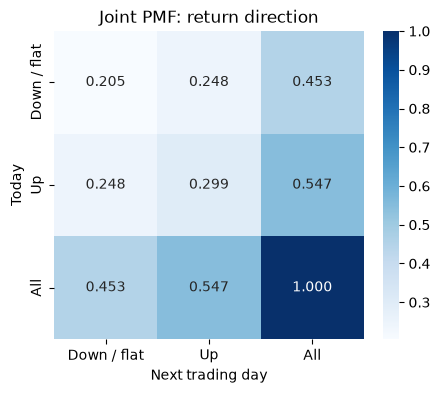

In [23]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df['direction_t'], df['direction_tp1'], normalize=True, margins=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [24]:
# Plot the conditional PMF
pd.crosstab(df['direction_t'],df['direction_tp1'], normalize= 'index')

direction_tp1,Down / flat,Up
direction_t,,
Down / flat,0.452507,0.547493
Up,0.453218,0.546782


<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

</div>

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- Subtract the marginal PMF of tomorrow's state from each row of the conditional PMF, and plot the result as a heatmap. If tomorrow's state were independent of today's, every row of the conditional PMF would equal this marginal. Which transitions are more likely than independence predicts, and which are less likely? Does knowing today's state change the forecast for tomorrow?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [28]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df['market_return_pct'], bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf], labels = return_categories)
df['return_bin'].value_counts()

return_bin
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

In [30]:
#make y_t and y_tp1 columns for the return bins
df['y_t'] = df['return_bin']
df['y_tp1'] =  df['return_bin'].shift(-1)

In [33]:
pd.crosstab(df['y_t'], df['y_tp1'], normalize= True, margins=True)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)
- Which are the most or least common?
  
  </div>

In [ ]:
#joint PMF with marginals

<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur? 

</div>

In [ ]:
#conditional PMF 
fig, ax = plt.subplots(figsize= (7,5))
sns.heatmap(pd.crosstab(df['y_t'], df['y_tp1']))

<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 
- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 
- Is it relatively easy or difficult to predict the next state?
</div>

In [ ]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True).sum(axis=0)
next_state_pmf

conditional
# subtract it from each row of the conditional PMF and plot as a heatmap

# hint: use .sub(next_state_pmf, axis='columns'), and a diverging colormap such as cmap='RdBu_r' with center=0

y_tp1
Large loss    0.104925
Small loss    0.283400
Near zero     0.130823
Small gain    0.372124
Large gain    0.108728
dtype: float64

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?
- Does knowing today's state change the forecast for tomorrow?
- How is this comparison different from comparing each row to a uniform PMF with probability .2?
</div>

In [ ]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)

# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t
df.groupby("y_t")["market_return_pct"].describe()

C:\Users\clair\AppData\Local\Temp\ipykernel_25516\1376590865.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("y_t")["market_return_pct"].describe()


,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-1.881153,1.120657,-17.41,-2.14,-1.53,-1.21,-1.00
Small loss,7452.0,-0.444300,0.249796,-0.99,-0.63,-0.40,-0.23,-0.10
Near zero,3441.0,0.004507,0.057960,-0.10,-0.05,0.01,0.05,0.10
Small gain,9785.0,0.455943,0.243158,0.11,0.25,0.42,0.64,1.00
Large gain,2859.0,1.803071,1.103548,1.01,1.19,1.45,1.95,15.67


<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 
- How do the min and max values for tomorrow vary across states? 
- Which states have the highest standard deviation for tomorrow's percent returns? 
- Describe any patterns in the volatility you notice.
</div>


### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [ ]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

In [ ]:
#joint PMF with marginals for the 21 quantile bins + plot as heatmap

In [ ]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

In [ ]:
# compute and plot the conditional

In [ ]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

In [ ]:
# compute the next day's min, mean, and max conditional on each bin

In [ ]:
#plot as lines on a graph against the bins

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

In [ ]:
#compute the next day's standard deviation, and plot it as a line graph against the bins. 

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market?
</div>